1. Choosing my language

In [1]:
LANG = "kin" 

## 2. Load the data
The data comes straight from the official AfriSenti GitHub repository, so nothing needs to be downloaded by hand.
The first time it runs, it also saves a copy in a `data/` folder so the notebook works offline afterwards.

In [2]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

BASE = "https://raw.githubusercontent.com/afrisenti-semeval/afrisent-semeval-2023/main/data"

def load(split):
    local = f"data/{LANG}/{split}.tsv"
    if os.path.exists(local):
        return pd.read_csv(local, sep="\t", quoting=3).dropna()
    df = pd.read_csv(f"{BASE}/{LANG}/{split}.tsv", sep="\t", quoting=3).dropna()
    os.makedirs(f"data/{LANG}", exist_ok=True)
    df.to_csv(local, sep="\t", index=False)
    return df

train, dev, test = load("train"), load("dev"), load("test")
print(f"Train: {len(train)}  Dev: {len(dev)}  Test: {len(test)}")
train.head()

Train: 3302  Dev: 827  Test: 1026


,tweet,label
0,@user @user @user @user @user @user @user Hhhh...,negative
1,"@user Amahano?! Ni impanuka, inkangu, inzara.....",negative
2,Ese umuntu aguhaye miliyoni 7 zidorali ngo ary...,negative
3,Ugira amagambo😏 kandi Ubwo wasanga nawe byagut...,negative
4,Ukuntu inama zose zikomeye zirikubera Mu Rwand...,negative


3. Explore Data

label
neutral     1257
negative    1146
positive     899
Name: count, dtype: int64


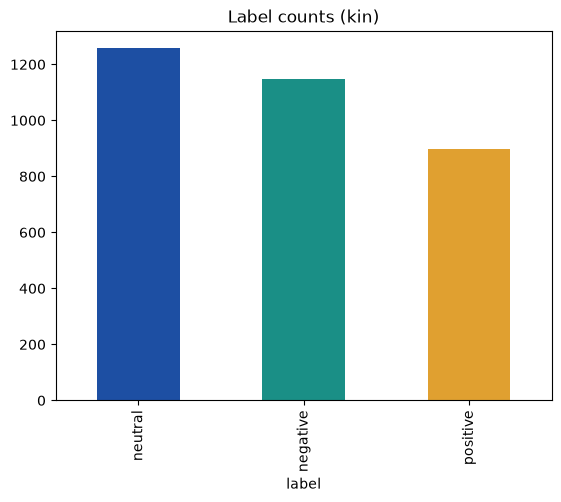

In [3]:
print(train["label"].value_counts())
train["label"].value_counts().plot(kind="bar", title=f"Label counts ({LANG})", color=["#1D4FA3", "#1A8F86", "#E0A030"])
plt.show()

## 4. Clean the text (preprocessing)
- **Normalization:** lowercase, fix spacing
- Remove `@user` mentions and links
- Shorten repeated letters (`hhhhhh` → `hh`)

No English stop-word list is used, because it does not fit this language.

In [4]:
def clean(text):
    text = text.lower()
    text = re.sub(r"@user", " ", text)
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

for df in (train, dev, test):
    df["clean"] = df["tweet"].apply(clean)

print("Before:", train["tweet"].iloc[0])
print("After: ", train["clean"].iloc[0])

Before: @user @user @user @user @user @user @user Hhhhhh ntabyihogoza, ubu x abo yishe bangana ik
After:  hh ntabyihogoza, ubu x abo yishe bangana ik


## 5. Turn words into numbers (TF-IDF)
Two kinds of features are combined:
- **Word features:** single words and word pairs
- **Character features:** small pieces of words, which help with spelling variation and long word forms

The vocabulary is learned from the **training data only**.

In [5]:
features = FeatureUnion([
    ("words", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
])
X_train = features.fit_transform(train["clean"])
X_dev = features.transform(dev["clean"])
X_test = features.transform(test["clean"])
print(f"Each tweet is now a vector of {X_train.shape[1]} numbers")

Each tweet is now a vector of 42872 numbers


## 6. Train and compare two models
The better model is chosen using the **dev** set.

In [6]:
models = {
    "Naive Bayes": MultinomialNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=3, class_weight="balanced"),
}
scores = {}
for name, model in models.items():
    model.fit(X_train, train["label"])
    scores[name] = f1_score(dev["label"], model.predict(X_dev), average="weighted")
    print(f"{name}: dev weighted F1 = {scores[name]:.3f}")

best_name = max(scores, key=scores.get)
best = models[best_name]
print("Best model:", best_name)

Naive Bayes: dev weighted F1 = 0.643
Logistic Regression: dev weighted F1 = 0.626
Best model: Naive Bayes


## 7. Evaluate on the test set
The test set is data the model has never seen.

              precision    recall  f1-score   support

    negative       0.57      0.71      0.63       355
     neutral       0.58      0.52      0.55       393
    positive       0.72      0.59      0.65       278

    accuracy                           0.61      1026
   macro avg       0.62      0.61      0.61      1026
weighted avg       0.61      0.61      0.60      1026



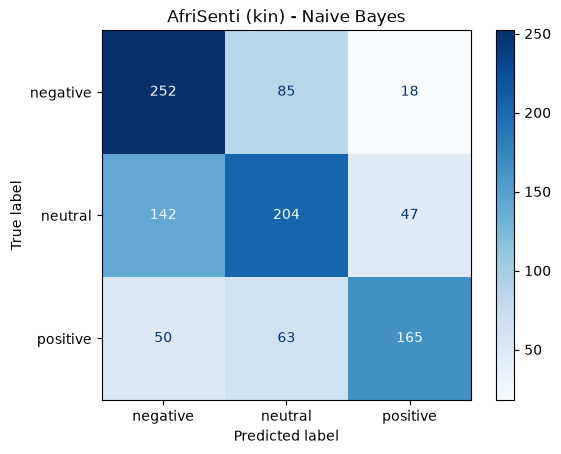

In [7]:
pred = best.predict(X_test)
print(classification_report(test["label"], pred))
ConfusionMatrixDisplay.from_predictions(test["label"], pred, cmap="Blues")
plt.title(f"AfriSenti ({LANG}) - {best_name}")
plt.show()

## 8. Explain: which words point to each label?

In [8]:
lr = models["Logistic Regression"]
names = features.get_feature_names_out()
word_idx = [i for i, n in enumerate(names) if n.startswith("words__")]
for c, label in enumerate(lr.classes_):
    top = sorted(word_idx, key=lambda i: lr.coef_[c][i], reverse=True)[:10]
    print(f"{label:9}:", ", ".join(names[i].replace("words__", "") for i in top))

negative : ngo, birababaje, ibaze, nabi, ari, cg, mubi, myanya, umunwa, tweet
neutral  : iki, gukora, na, nari, ese, wa, akwiye, uvuze, cyane cyane, biterwa
positive : mwiza, nziza, amahoro, humura, uwiteka, imana, ugomba, neza, sinjya, ibyiza


## 9. Study the mistakes (your native-speaker advantage)
Look for patterns: sarcasm, mixing languages, emojis, or labels that look wrong.

In [9]:
test["pred"] = pred
mistakes = test[test["label"] != test["pred"]]
print(f"{len(mistakes)} mistakes out of {len(test)}")
pd.set_option("display.max_colwidth", 150)
mistakes[["tweet", "label", "pred"]].head(15)

405 mistakes out of 1026


,tweet,label,pred
0,@user @user @user Kubeshya ntabwo Ari icyaha uretse iyo urukiko rubyemeje,neutral,negative
3,@user @user Aha niho bita ku kirenge ra?,neutral,negative
4,Hari abantu bahisemo brain kuyikoresha nk’amasogisi mw’iyi minsi😂😂😂,negative,neutral
8,Njye Nasura hariya hantu yezu yakoreye i Gitangaza gikomeye cyo guhindura amazi divayi. Ingwasi y'icyaka ntitwari kuzayikira😂 https://t.co/BAlgc46bRj,negative,neutral
12,@user na @user muze mumpe Congs ndyame! 😂,positive,neutral
13,@user 😂😂😂poleni gisa 👊 nta storm idashira ngo hacye🤗,positive,negative
16,@user gahunda nugukomezanya na #Messi wowe ubyumva ut?,neutral,negative
22,Niba usobanukiwe ibimenyetso ubona ku bikarito? Dore ubusobanuro ngubu! #RwOT #Rwanda #Rwandan #menya https://t.co/m4Eln8Wmkd,positive,neutral
24,@user @user @user Harya nangahe ngo nyohereze,positive,neutral
25,@user @user Nuko agenda yitura hasi ntiyamenyereye imisozi gusa banza uruta Jackson,neutral,negative


## 10. Try your own sentences

In [13]:
my_sentences = [
    "Ibiryo birabishye",
    "Mperekeza m'umugi gushaka impano ya mama.",
    "Nibajije uko byagenze biranyobera pe.",
]
for s, p in zip(my_sentences, best.predict(features.transform([clean(s) for s in my_sentences]))):
    print(f"{p:9} <- {s}")

negative  <- Ibiryo birabishye
positive  <- Mperekeza m'umugi gushaka impano ya mama.
neutral   <- Nibajije uko byagenze biranyobera pe.
